In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#LOADING DATASET
df=pd.read_csv('flood_risk_dataset_india.csv')
df.head()

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465433,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


In [2]:
print(df.describe())
print(df.info())
print(df.isnull().sum())


           Latitude     Longitude  Rainfall (mm)  Temperature (°C)  \
count  10000.000000  10000.000000   10000.000000      10000.000000   
mean      22.330627     82.631366     150.015118         29.961401   
std        8.341274      8.389542      86.032127          8.669838   
min        8.000337     68.004575       0.014437         15.000166   
25%       15.143537     75.364428      76.124373         22.405717   
50%       22.283330     82.671007     150.620428         30.000907   
75%       29.460184     89.937897     223.402156         37.413488   
max       36.991813     96.997820     299.970293         44.993681   

       Humidity (%)  River Discharge (m³/s)  Water Level (m)  Elevation (m)  \
count  10000.000000            10000.000000     10000.000000   10000.000000   
mean      59.749104             2515.722946         5.017881    4417.138177   
std       23.142734             1441.706442         2.876579    2530.245421   
min       20.001339                0.042161         0

In [3]:
#CLEANING COLUMN NAMES
df.columns = df.columns.str.replace(" ", "_").str.title()
print(df.columns)


Index(['Latitude', 'Longitude', 'Rainfall_(Mm)', 'Temperature_(°C)',
       'Humidity_(%)', 'River_Discharge_(M³/S)', 'Water_Level_(M)',
       'Elevation_(M)', 'Land_Cover', 'Soil_Type', 'Population_Density',
       'Infrastructure', 'Historical_Floods', 'Flood_Occurred'],
      dtype='str')


In [4]:
#checking for duplicates values
count1 =df.duplicated().sum()
print(count1)
df=df.drop_duplicates()

count =df.duplicated().sum()
print(count)

0
0


In [5]:
#Saparating categorical and continuous columns
cat=[]
con=[]
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        con.append(col)
    else:
       cat.append(col)

print(cat)
print(con)

['Land_Cover', 'Soil_Type']
['Latitude', 'Longitude', 'Rainfall_(Mm)', 'Temperature_(°C)', 'Humidity_(%)', 'River_Discharge_(M³/S)', 'Water_Level_(M)', 'Elevation_(M)', 'Population_Density', 'Infrastructure', 'Historical_Floods', 'Flood_Occurred']


In [6]:
#Missing values
missingnull=df.isnull().sum()
print(missingnull)

Latitude                  0
Longitude                 0
Rainfall_(Mm)             0
Temperature_(°C)          0
Humidity_(%)              0
River_Discharge_(M³/S)    0
Water_Level_(M)           0
Elevation_(M)             0
Land_Cover                0
Soil_Type                 0
Population_Density        0
Infrastructure            0
Historical_Floods         0
Flood_Occurred            0
dtype: int64


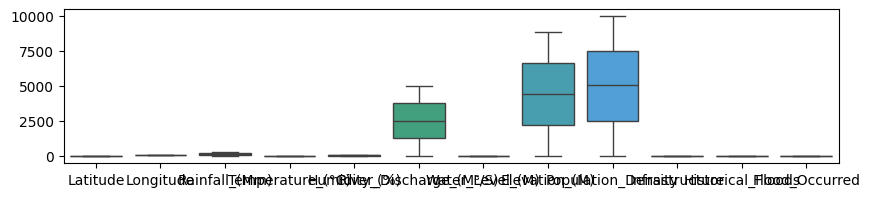

In [7]:
#checking for outliers in continuous columns
plt.figure(figsize=(10,2))
sns.boxplot(data=df[con])
plt.show()


In [8]:
Q1=df[con].quantile(0.25)
Q3=df[con].quantile(0.75)
IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
print("Q1 :",Q1)
print("Q3 :",Q3)
print("IOR :",IQR)
print("LOWER LIMIT:",lower_limit)
print("UPPER LIMIT:",upper_limit)


Q1 : Latitude                    15.143537
Longitude                   75.364428
Rainfall_(Mm)               76.124373
Temperature_(°C)            22.405717
Humidity_(%)                39.541778
River_Discharge_(M³/S)    1284.782376
Water_Level_(M)              2.538847
Elevation_(M)             2229.681903
Population_Density        2491.766601
Infrastructure               0.000000
Historical_Floods            0.000000
Flood_Occurred               0.000000
Name: 0.25, dtype: float64
Q3 : Latitude                    29.460184
Longitude                   89.937897
Rainfall_(Mm)              223.402156
Temperature_(°C)            37.413488
Humidity_(%)                80.038163
River_Discharge_(M³/S)    3767.229862
Water_Level_(M)              7.524692
Elevation_(M)             6616.729066
Population_Density        7474.228752
Infrastructure               1.000000
Historical_Floods            1.000000
Flood_Occurred               1.000000
Name: 0.75, dtype: float64
IOR : Latitude          

In [9]:
#filling missing values in continuous columns with median
for col in con:
    median = df[col].median()
    df[col] = df[col].fillna(median)

In [10]:
#filling missing values in categorical columns with mode
for col in cat:
    mode = df[col].mode()[0]
    df[col] = df[col].fillna(mode)

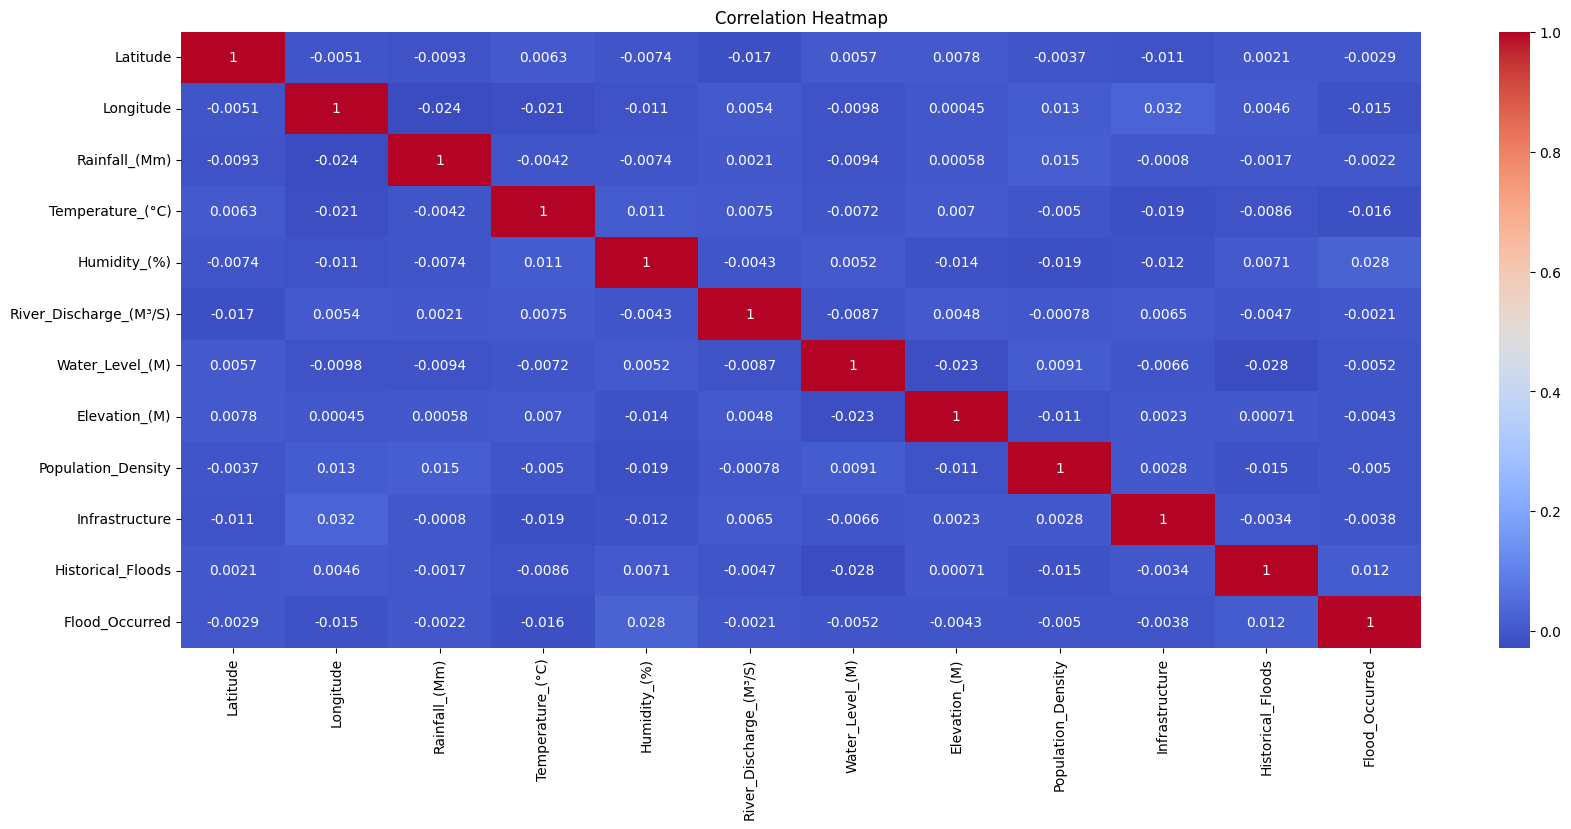

In [11]:
#Visualizing correlation between continuous variables
plt.figure(figsize=(20,8))
sns.heatmap(df[con].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [12]:
#scaling continuous variables
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_std = pd.DataFrame(
    scaler.fit_transform(df[con]),
    columns=con
)

df_std.head()

,Latitude,Longitude,Rainfall_(Mm),Temperature_(°C),Humidity_(%),River_Discharge_(M³/S),Water_Level_(M),Elevation_(M),Population_Density,Infrastructure,Historical_Floods,Flood_Occurred
0,-0.415900,-0.452465,0.801884,0.482494,-0.684316,1.193409,0.833556,-1.596634,0.782416,0.996008,-0.997403,0.988664
1,1.587377,-0.593258,-1.100359,-0.136414,-1.389866,-0.029923,1.318694,1.151515,0.650929,-1.004008,1.002603,-1.011466
2,0.826917,-1.135149,-0.534981,1.611824,-1.280827,-1.067119,-0.134223,-0.873977,-0.228955,0.996008,1.002603,0.988664
3,0.363328,0.355146,0.569224,-0.968007,-1.093072,0.809835,-0.739142,-0.752874,0.396053,0.996008,1.002603,-1.011466
4,-1.175669,-0.096466,-0.062635,0.308475,-1.013623,-0.292954,-0.636001,-0.954627,0.397751,0.996008,-0.997403,-1.011466


In [13]:
#Converting categorical columns to category 
for col in cat:
    df[col] = df[col].astype("category")
dummies = pd.get_dummies(df[cat].astype("category"), dtype=int, drop_first=True)

In [14]:
final_df = pd.concat([df_std, dummies], axis=1)

final_df.head()

,Latitude,Longitude,Rainfall_(Mm),Temperature_(°C),Humidity_(%),River_Discharge_(M³/S),Water_Level_(M),Elevation_(M),Population_Density,Infrastructure,Historical_Floods,Flood_Occurred,Land_Cover_Desert,Land_Cover_Forest,Land_Cover_Urban,Land_Cover_Water Body,Soil_Type_Loam,Soil_Type_Peat,Soil_Type_Sandy,Soil_Type_Silt
0,-0.415900,-0.452465,0.801884,0.482494,-0.684316,1.193409,0.833556,-1.596634,0.782416,0.996008,-0.997403,0.988664,0,0,0,1,0,0,0,0
1,1.587377,-0.593258,-1.100359,-0.136414,-1.389866,-0.029923,1.318694,1.151515,0.650929,-1.004008,1.002603,-1.011466,0,1,0,0,0,1,0,0
2,0.826917,-1.135149,-0.534981,1.611824,-1.280827,-1.067119,-0.134223,-0.873977,-0.228955,0.996008,1.002603,0.988664,0,0,0,0,1,0,0,0
3,0.363328,0.355146,0.569224,-0.968007,-1.093072,0.809835,-0.739142,-0.752874,0.396053,0.996008,1.002603,-1.011466,1,0,0,0,0,0,1,0
4,-1.175669,-0.096466,-0.062635,0.308475,-1.013623,-0.292954,-0.636001,-0.954627,0.397751,0.996008,-0.997403,-1.011466,0,0,0,0,1,0,0,0


In [15]:
print(final_df.shape)
print(final_df.head())

(10000, 20)
   Latitude  Longitude  Rainfall_(Mm)  Temperature_(°C)  Humidity_(%)  \
0 -0.415900  -0.452465       0.801884          0.482494     -0.684316   
1  1.587377  -0.593258      -1.100359         -0.136414     -1.389866   
2  0.826917  -1.135149      -0.534981          1.611824     -1.280827   
3  0.363328   0.355146       0.569224         -0.968007     -1.093072   
4 -1.175669  -0.096466      -0.062635          0.308475     -1.013623   

   River_Discharge_(M³/S)  Water_Level_(M)  Elevation_(M)  Population_Density  \
0                1.193409         0.833556      -1.596634            0.782416   
1               -0.029923         1.318694       1.151515            0.650929   
2               -1.067119        -0.134223      -0.873977           -0.228955   
3                0.809835        -0.739142      -0.752874            0.396053   
4               -0.292954        -0.636001      -0.954627            0.397751   

   Infrastructure  Historical_Floods  Flood_Occurred  Land_Cov

In [ ]:
final_df.to_csv('final_df.csv', index=False)

: 